# Analyse Expérimentale Huffman Dynamique

## Fonctions pour graphes

In [3]:
import os
def show_ratio(txt_rel, bin_rel, label=None):
    txt_path = os.path.join("..", *txt_rel.split("/"))
    bin_path = os.path.join("..", *bin_rel.split("/"))
    txt_size = os.path.getsize(txt_path) if os.path.exists(txt_path) else 0
    bin_size = os.path.getsize(bin_path) if os.path.exists(bin_path) else 0
    if not txt_size or not bin_size:
        print(f"{label or txt_rel}: fichiers introuvables ou taille nulle")
        return
    ratio = bin_size / txt_size
    taux = 1 - ratio
    facteur = txt_size / bin_size
    name = label or os.path.basename(txt_path)
    print(f"{name}: {bin_size}/{txt_size} octets | taux: {taux:.2%} | facteur: {facteur:.2f}x")

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def load_log_file(filename):
    """
    Charge un fichier de log (compression.txt ou decompression.txt)
    
    Format attendu : input_file;output_file;input_size;output_size;rate;time_ms
    """
    columns = ['input_file', 'output_file', 'input_size', 'output_size', 'rate', 'time_ms']
    df = pd.read_csv(filename, sep=';', names=columns, encoding='utf-8')
    return df

In [5]:
def plot_time_size():
    """
    Crée des graphiques montrant le temps de compression et décompression en fonction de la taille des fichiers
    """
    # Charger les données
    df_compression = load_log_file('../compression.txt')
    df_decompression = load_log_file('../decompression.txt')
    
    # Créer une figure avec 2 sous-graphiques
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ========== GRAPHIQUE 1 : Compression ==========
    ax1 = axes[0]
    
    # Scatter plot
    ax1.scatter(df_compression['input_size'], df_compression['time_ms'], 
                alpha=0.6, s=50, color='blue', label='Points de données')
    
    # Ligne de tendance (régression linéaire)
    z = np.polyfit(df_compression['input_size'], df_compression['time_ms'], 1)
    p = np.poly1d(z)
    ax1.plot(df_compression['input_size'], p(df_compression['input_size']), 
             "r--", linewidth=2, label=f'Tendance: y={z[0]:.6f}x+{z[1]:.2f}')
    
    ax1.set_xlabel('Taille du fichier (octets)', fontsize=12)
    ax1.set_ylabel('Temps de compression (ms)', fontsize=12)
    ax1.set_title('Temps de compression = f(Taille fichier)', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # ========== GRAPHIQUE 2 : Décompression ==========
    ax2 = axes[1]
    
    # Scatter plot
    ax2.scatter(df_decompression['input_size'], df_decompression['time_ms'], 
                alpha=0.6, s=50, color='green', label='Points de données')
    
    # Ligne de tendance
    z2 = np.polyfit(df_decompression['input_size'], df_decompression['time_ms'], 1)
    p2 = np.poly1d(z2)
    ax2.plot(df_decompression['input_size'], p2(df_decompression['input_size']), 
             "r--", linewidth=2, label=f'Tendance: y={z2[0]:.6f}x+{z2[1]:.2f}')
    
    ax2.set_xlabel('Taille du fichier compressé (octets)', fontsize=12)
    ax2.set_ylabel('Temps de décompression (ms)', fontsize=12)
    ax2.set_title('Temps de décompression = f(Taille fichier)', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.tight_layout()
    plt.savefig('temps_taille.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : temps_taille.png")
    plt.show()


def plot_comparison():
    """
    Compare compression et décompression sur le même graphique
    """
    # Charger les données
    df_comp = load_log_file('../compression.txt')
    df_decomp = load_log_file('../decompression.txt')
    
    plt.figure(figsize=(10, 6))
    
    # Compression
    plt.scatter(df_comp['input_size'], df_comp['time_ms'], 
                alpha=0.6, s=50, color='blue', label='Compression')
    
    # Décompression
    plt.scatter(df_decomp['input_size'], df_decomp['time_ms'], 
                alpha=0.6, s=50, color='green', label='Décompression')
    
    plt.xlabel('Taille du fichier (octets)', fontsize=12)
    plt.ylabel('Temps (ms)', fontsize=12)
    plt.title('Comparaison Compression vs Décompression', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('comparaison_temps.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : comparaison_temps.png")
    plt.show()


def plot_compression_rate():
    """
    Graphique du taux de compression en fonction de la taille
    """
    df = load_log_file('../compression.txt')
    
    plt.figure(figsize=(10, 6))
    
    plt.scatter(df['input_size'], df['rate'], alpha=0.6, s=50, color='purple')
    
    # Ligne horizontale à 1.0 (pas de compression)
    plt.axhline(y=1.0, color='r', linestyle='--', linewidth=1, label='Pas de compression (rate=1.0)')
    
    plt.xlabel('Taille du fichier original (octets)', fontsize=12)
    plt.ylabel('Taux de compression', fontsize=12)
    plt.title('Taux de compression = f(Taille fichier)', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('taux_compression.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : taux_compression.png")
    plt.show()


def plot_all_stats():
    """
    Crée une figure avec 4 graphiques pour une vue complète
    """
    df_comp = load_log_file('../compression.txt')
    df_decomp = load_log_file('../decompression.txt')
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Temps compression en fonction taille
    axes[0, 0].scatter(df_comp['input_size'], df_comp['time_ms'], alpha=0.6, color='blue')
    axes[0, 0].set_xlabel('Taille (octets)')
    axes[0, 0].set_ylabel('Temps (ms)')
    axes[0, 0].set_title('Compression : Temps compression = f(Taille)')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Temps décompression ven fonction taille
    axes[0, 1].scatter(df_decomp['input_size'], df_decomp['time_ms'], alpha=0.6, color='green')
    axes[0, 1].set_xlabel('Taille (octets)')
    axes[0, 1].set_ylabel('Temps (ms)')
    axes[0, 1].set_title('Décompression : Temps décompression = f(Taille)')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Taux de compression en fonction taille
    axes[1, 0].scatter(df_comp['input_size'], df_comp['rate'], alpha=0.6, color='purple')
    axes[1, 0].axhline(y=1.0, color='r', linestyle='--', linewidth=1)
    axes[1, 0].set_xlabel('Taille (octets)')
    axes[1, 0].set_ylabel('Taux de compression')
    axes[1, 0].set_title('Taux de compression = f(Taille)')
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Distribution des taux de compression
    axes[1, 1].hist(df_comp['rate'], bins=20, alpha=0.7, color='orange', edgecolor='black')
    axes[1, 1].axvline(x=df_comp['rate'].mean(), color='r', linestyle='--', 
                       linewidth=2, label=f'Moyenne: {df_comp["rate"].mean():.3f}')
    axes[1, 1].set_xlabel('Taux de compression')
    axes[1, 1].set_ylabel('Fréquence')
    axes[1, 1].set_title('Distribution des taux de compression')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('analyse_complete.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : analyse_complete.png")
    plt.show()


def print_statistics():
    """
    Affiche des statistiques résumées
    """
    df_comp = load_log_file('../compression.txt')
    df_decomp = load_log_file('../decompression.txt')
    
    print("=" * 30)
    print("STATISTIQUES DE COMPRESSION")
    print("=" * 30)
    print(f"Nombre de fichiers : {len(df_comp)}")
    print(f"Taux moyen : {df_comp['rate'].mean():.5f}")
    print(f"Temps moyen : {df_comp['time_ms'].mean():.2f} ms")
    print(f"Taille moyenne entrée : {df_comp['input_size'].mean():.0f} octets")
    print(f"Réduction moyenne : {(1 - df_comp['rate'].mean()) * 100:.2f}%")
    
    print("\n" + "=" * 30)
    print("STATISTIQUES DE DÉCOMPRESSION")
    print("=" * 30)
    print(f"Nombre de fichiers : {len(df_decomp)}")
    print(f"Temps moyen : {df_decomp['time_ms'].mean():.2f} ms")
    
    # Comparaison vitesse
    ratio = df_comp['time_ms'].mean() / df_decomp['time_ms'].mean()
    print(f"\nLa décompression est {ratio:.2f}x plus rapide que la compression")


## Résultats expérimentaux sur fichiers textuels existants (question 8) 
Bibliothèques de textes utilisée : projet Gutenberg, cf rapport pour sources

Si on veut uniquement les informations de compression des fichiers textuels  


In [ ]:
!echo -n > ../compression.txt && echo -n > ../decompression.txt

#### Texte Français (NdP - Hugo) -- autour de 15 secondes

In [10]:
!../compresser ../texts/francais.txt ../texts/bintexts/francais.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/francais.huff
Compression ../texts/francais.txt ...
Fichier encodé avec succès: ../texts/francais.txt -> ../texts/bintexts/francais.huff


In [ ]:
# Français (NdP - Hugo)
show_ratio("texts/francais.txt", "texts/bintexts/francais.bin", label="Français (Hugo)")

#### Texte Français 2 (Blaise Pascal) -- autour de 4 secondes

In [11]:
!../compresser ../texts/Blaise_Pascal/Blaise_Pascal.txt ../texts/bintexts/Blaise_Pascal.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/Blaise_Pascal.huff
Compression ../texts/Blaise_Pascal/Blaise_Pascal.txt ...
Fichier encodé avec succès: ../texts/Blaise_Pascal/Blaise_Pascal.txt -> ../texts/bintexts/Blaise_Pascal.huff


In [ ]:
# Blaise Pascal
show_ratio("texts/Blaise_Pascal/Blaise_Pascal.txt", "texts/Blaise_Pascal/Blaise_Pascal.txt.huff", label="Blaise Pascal")

#### Texte Anglais -- autour de 12 secondes

In [12]:
!../compresser ../texts/anglais.txt ../texts/bintexts/anglais.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/anglais.huff
Compression ../texts/anglais.txt ...
Fichier encodé avec succès: ../texts/anglais.txt -> ../texts/bintexts/anglais.huff


In [ ]:
show_ratio("texts/anglais.txt", "texts/bintexts/anglais.bin", label="Anglais")

#### Texte Grec -- autour de 45 secondes

In [13]:
!../compresser ../texts/grec.txt ../texts/bintexts/grec.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/grec.huff
Compression ../texts/grec.txt ...
Fichier encodé avec succès: ../texts/grec.txt -> ../texts/bintexts/grec.huff


In [ ]:
show_ratio("texts/grec.txt", "texts/bintexts/grec.bin", label="Grec")

#### Texte Russe -- autour de 8 secondes

In [14]:
!../compresser ../texts/russe.txt ../texts/bintexts/russe.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/russe.huff
Compression ../texts/russe.txt ...
Fichier encodé avec succès: ../texts/russe.txt -> ../texts/bintexts/russe.huff


In [ ]:
show_ratio("texts/russe.txt", "texts/bintexts/russe.bin", label="Russe")

#### Texte Chinois -- autour de 5 min

In [15]:
!../compresser ../texts/chinois.txt ../texts/bintexts/chinois.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/chinois.huff
Compression ../texts/chinois.txt ...
Fichier encodé avec succès: ../texts/chinois.txt -> ../texts/bintexts/chinois.huff


In [ ]:
show_ratio("texts/chinois.txt", "texts/bintexts/chinois.bin", label="Chinois")

STATISTIQUES DE COMPRESSION
Nombre de fichiers : 6
Taux moyen : 0.48044
Temps moyen : 69708.73 ms
Taille moyenne entrée : 592543 octets
Réduction moyenne : 51.96%

STATISTIQUES DE DÉCOMPRESSION
Nombre de fichiers : 0
Temps moyen : nan ms

La décompression est nanx plus rapide que la compression
Graphique sauvegardé : analyse_complete.png


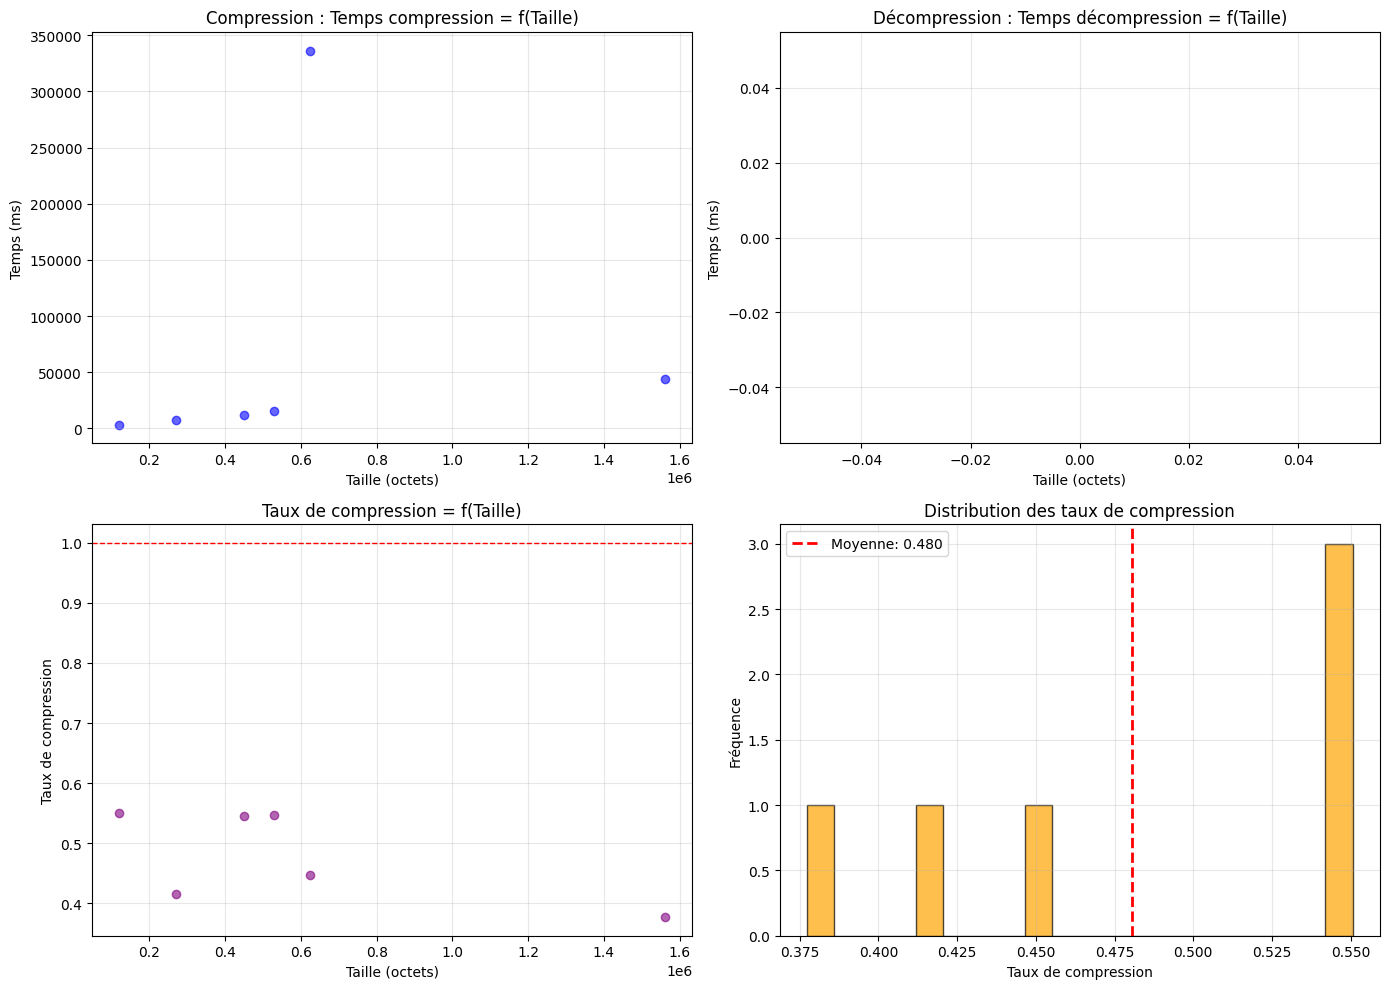

In [18]:
try:
    print_statistics()
    plot_all_stats()
except FileNotFoundError:
    print("Des cellules précédentes n'ont pas été exécutées")

## Résultats expérimentaux sur fichiers textuels générés (question 9)
On se sert à présent de fichiers textuels qu'on génère aléatoirement grâce au script generer.sh 
(cf rapport pour explication plus détaillée de celui-ci)

In [ ]:
!../generer.sh --help

Si on veut uniquement les informations de compression des fichiers aléatoires  


In [ ]:
!echo -n > ../compression.txt && echo -n > ../decompression.txt

In [23]:
!../generer.sh 10 random 

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 10
Base des noms      : random

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random8.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random6.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random1.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random9.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random0.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random5.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random4.txt' généré (13000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random7.txt' généré

In [24]:
!../generer.sh 5 random0 5000

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 5
Base des noms      : random0
Taille par fichier : 5000 caractères

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random02.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random00.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random01.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random03.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random04.txt' généré (5000 caractères).

5 fichiers générés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts

COMPRESSION DES FICHIERS
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random00.huff
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random01.huff
Le fichier de sortie n'existai

In [25]:
!../generer.sh 3 random00 10000 'latin:0.7,emojis:0.2'

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 3
Base des noms      : random00
Taille par fichier : 10000 caractères
Distribution       : latin:0.7,emojis:0.2

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random001.txt' généré (10000 caractères).Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random000.txt' généré (10000 caractères).

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random002.txt' généré (10000 caractères).

3 fichiers générés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts

COMPRESSION DES FICHIERS
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random000.huff
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random001.huff
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random002.huff
Compression random00.txt ...
Compression random000.txt ...
Compression random001.txt ...
Compression random002.txt ...
Fichier encodé a

In [26]:
!../generer.sh 1 random000 1000 'latin:0,emojis:0.2,japanese:0.5,korean:0.2'

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 1
Base des noms      : random000
Taille par fichier : 1000 caractères
Distribution       : latin:0,emojis:0.2,japanese:0.5,korean:0.2

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random0000.txt' généré (1000 caractères).

1 fichiers générés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts

COMPRESSION DES FICHIERS
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random0000.huff
Compression random000.txt ...
Compression random0000.txt ...
Fichier encodé avec succès: random0000.txt -> ./bintexts/random0000.huff
Fichier encodé avec succès: random000.txt -> ./bintexts/random000.huff

Tous les fichiers ont été compressés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/bintexts


STATISTIQUES DE COMPRESSION
Nombre de fichiers : 28
Taux moyen : 0.53699
Temps moyen : 19629.17 ms
Taille moyenne entrée : 145896 octets
Réduction moyenne : 46.30%

STATISTIQUES DE DÉCOMPRESSION
Nombre de fichiers : 0
Temps moyen : nan ms

La décompression est nanx plus rapide que la compression
Graphique sauvegardé : analyse_complete.png


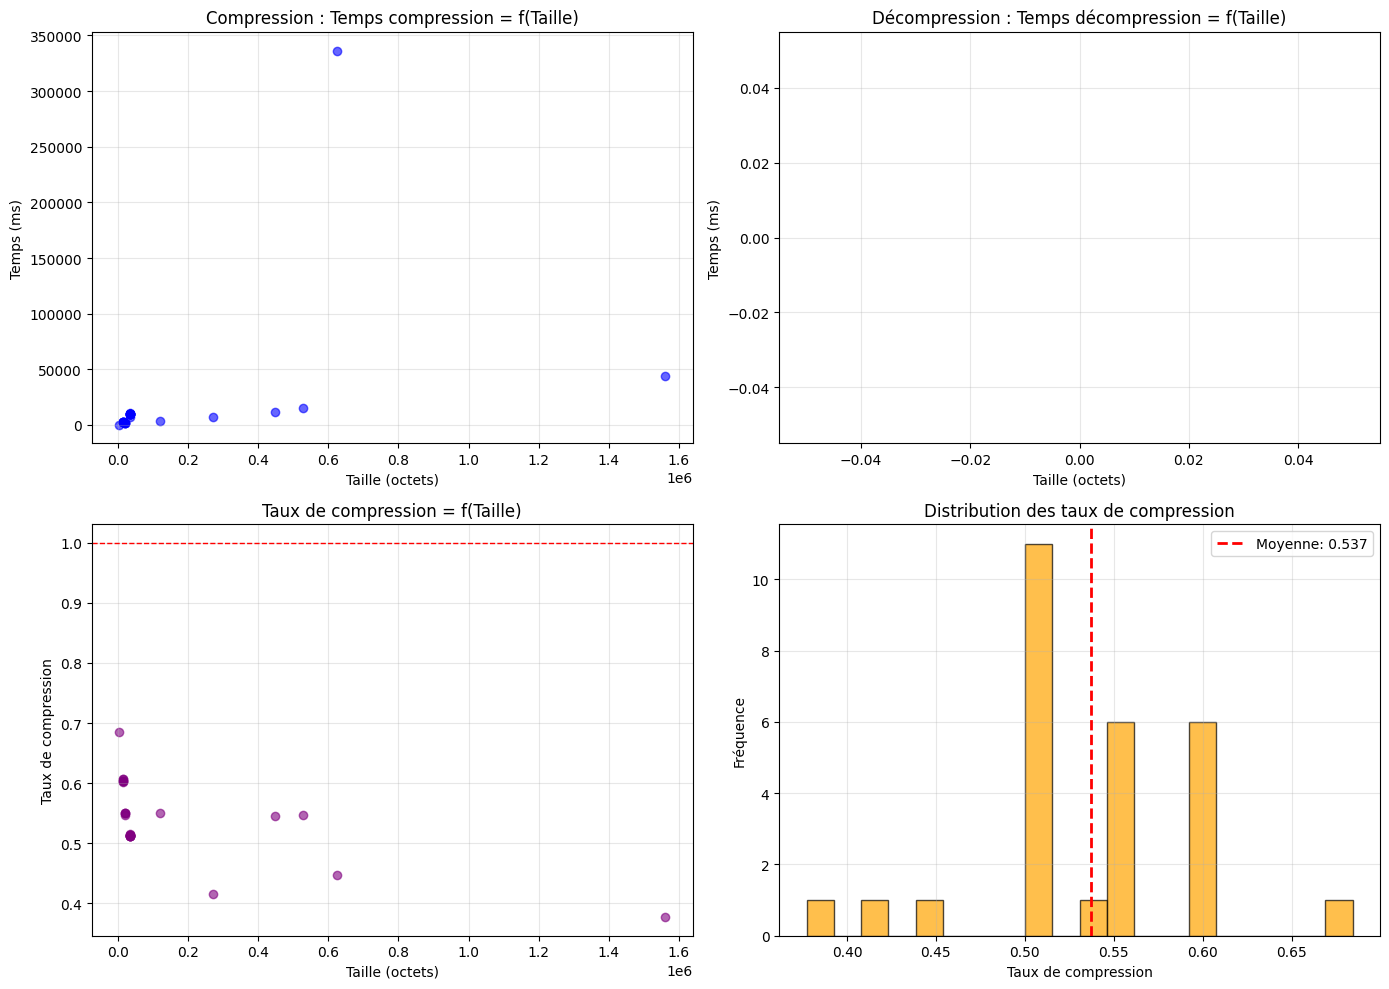

In [27]:
try:
    print_statistics()
    plot_all_stats()
except FileNotFoundError:
    print("Des cellules précédentes n'ont pas été exécutées")

## Résultats expérimentaux sur fichiers non textuels (question 10) ###
Enfin, on fait nos dernières expérimentations en utilisant des fichiers qui contiennent
de l’information sous une autre forme : du code. 

On utilise ici des fichiers .py, .sh, .ipynb, .md : on se servira tout simplement de fichiers de code présent dans ce projet.


In [ ]:
# si on veut uniquement les informations de compression des fichiers non textuels  
!echo -n > ../compression.txt && echo -n > ../decompression.txt

#### generate.py -- autour de 1 seconde

In [28]:
!../compresser ../src/generate.py ../texts/bintexts/generate.huff 

Compression ../src/generate.py ...
Fichier encodé avec succès: ../src/generate.py -> ../texts/bintexts/generate.huff


#### Node.py -- autour de 0.5 seconde

In [29]:
!../compresser ../src/Node.py ../texts/bintexts/Node.huff

Compression ../src/Node.py ...
Fichier encodé avec succès: ../src/Node.py -> ../texts/bintexts/Node.huff


#### utils.py -- autour de 0.5 seconde

In [30]:
!../compresser ../src/utils.py ../texts/bintexts/utils.huff

Compression ../src/utils.py ...
Fichier encodé avec succès: ../src/utils.py -> ../texts/bintexts/utils.huff


#### tests/test.ipynb -- autour de 0.7 seconde

In [31]:
!../compresser ../tests/tests.ipynb ../texts/bintexts/tests.ipynb

Compression ../tests/tests.ipynb ...
Fichier encodé avec succès: ../tests/tests.ipynb -> ../texts/bintexts/tests.ipynb


#### README.md -- autour de 0.3 seconde

In [32]:
!../compresser ../README.md ../texts/bintexts/README.huff

Compression ../README.md ...
Fichier encodé avec succès: ../README.md -> ../texts/bintexts/README.huff


#### generer.sh -- autour de 0.3 seconde

In [33]:
!../compresser ../generer.sh ../texts/bintexts/generer.huff

Compression ../generer.sh ...
Fichier encodé avec succès: ../generer.sh -> ../texts/bintexts/generer.huff


STATISTIQUES DE COMPRESSION
Nombre de fichiers : 34
Taux moyen : 0.55475
Temps moyen : 16211.96 ms
Taille moyenne entrée : 121575 octets
Réduction moyenne : 44.52%

STATISTIQUES DE DÉCOMPRESSION
Nombre de fichiers : 0
Temps moyen : nan ms

La décompression est nanx plus rapide que la compression
Graphique sauvegardé : analyse_complete.png


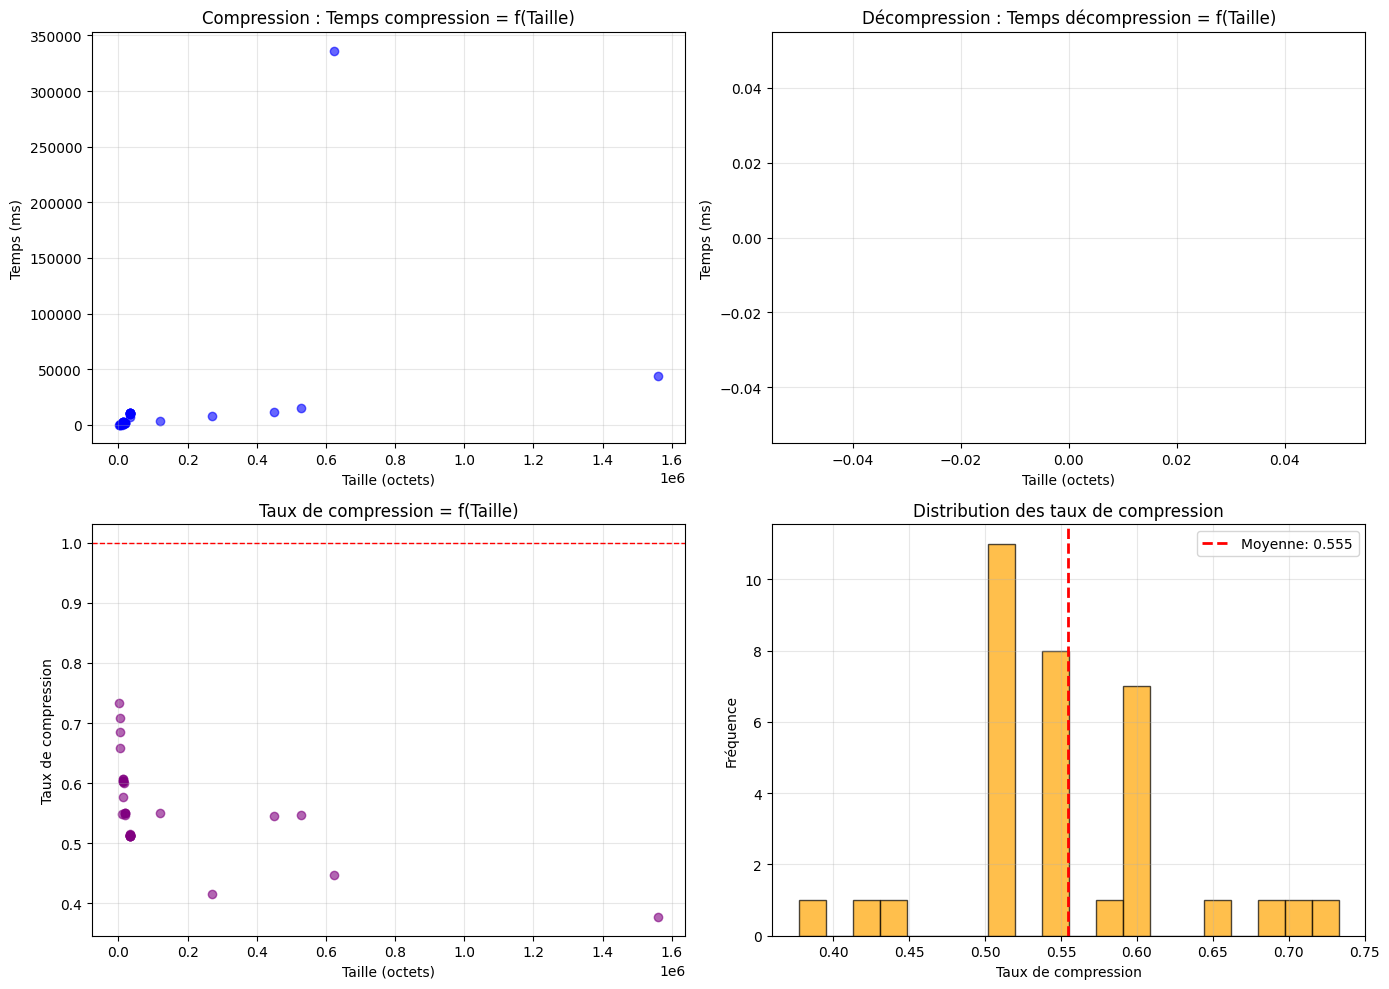

In [34]:
try:
    print_statistics()
    plot_all_stats()
except FileNotFoundError:
    print("Des cellules précédentes n'ont pas été exécutées")

In [38]:
# // Compter le nb de caractères uniques
!python3 -c "with open('../texts/analyse/symboles/sym_5000.txt', 'r', encoding='utf-8') as f: content = f.read(); unique_symbols = set(content); print(f'Nombre de symboles différents: {len(unique_symbols)}')"

Nombre de symboles différents: 1695


Nombre de fichiers trouvés: 110
Plage de longueurs: 1000 - 100000
Plage de temps: 92.43 - 7734.32 ms


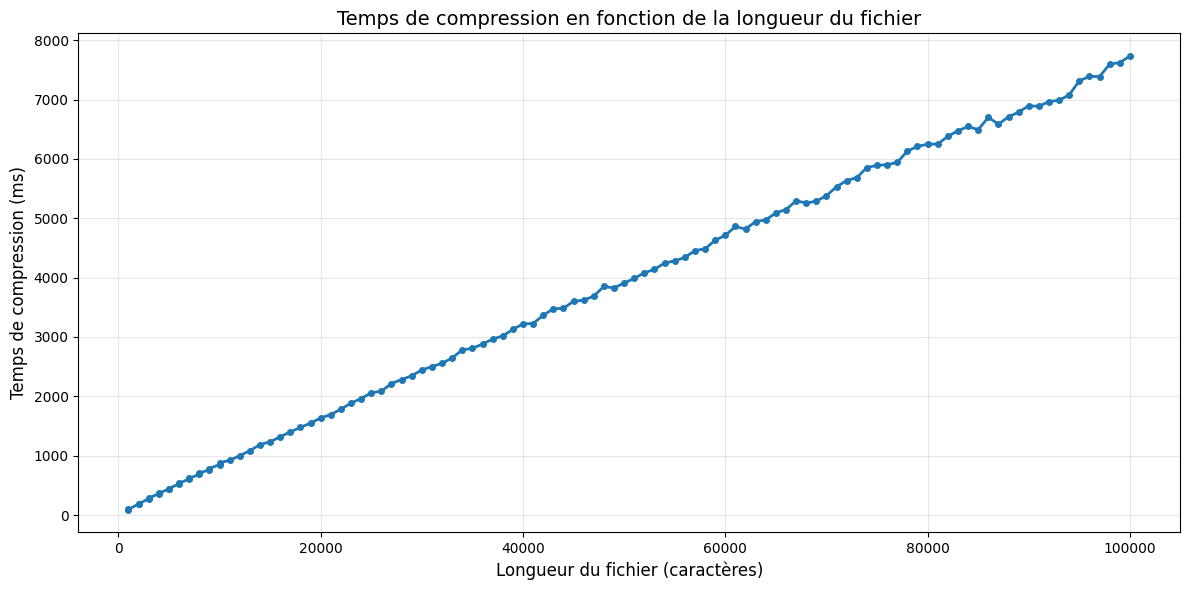

In [ ]:
import matplotlib.pyplot as plt
import re

# Lire le fichier de compression
data = []
with open('../compression.txt', 'r') as f:
    for line in f:
        # Chercher les lignes qui correspondent aux fichiers analyse/len_*.txt
        if 'analyse/len_' in line and '.txt' in line:
            parts = line.strip().split(';')
            filename = parts[0]
            # Extraire la longueur du nom du fichier (avec ou sans -0)
            match = re.search(r'len_(\d+)(?:-0)?\.txt', filename)
            if match:
                length = int(match.group(1))
                # La dernière valeur est le temps de compression
                compression_time = float(parts[-1])
                data.append((length, compression_time))

# Trier les données par longueur
data.sort(key=lambda x: x[0])

# Séparer les données pour le graphique
lengths = [d[0] for d in data]
times = [d[1] for d in data]

print(f"Nombre de fichiers trouvés: {len(data)}")
if data:
    print(f"Plage de longueurs: {min(lengths)} - {max(lengths)}")
    print(f"Plage de temps: {min(times):.2f} - {max(times):.2f} ms")

# Créer le graphique
plt.figure(figsize=(12, 6))
plt.plot(lengths, times, marker='o', linestyle='-', linewidth=2, markersize=4)
plt.xlabel('Longueur du fichier (caractères)', fontsize=12)
plt.ylabel('Temps de compression (ms)', fontsize=12)
plt.title('Temps de compression en fonction de la longueur du fichier', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Afficher le graphique
plt.show()


Nombre de fichiers trouvés: 65
Plage de longueurs: 10 - 3000
Plage de temps: 23.46 - 4527.09 ms


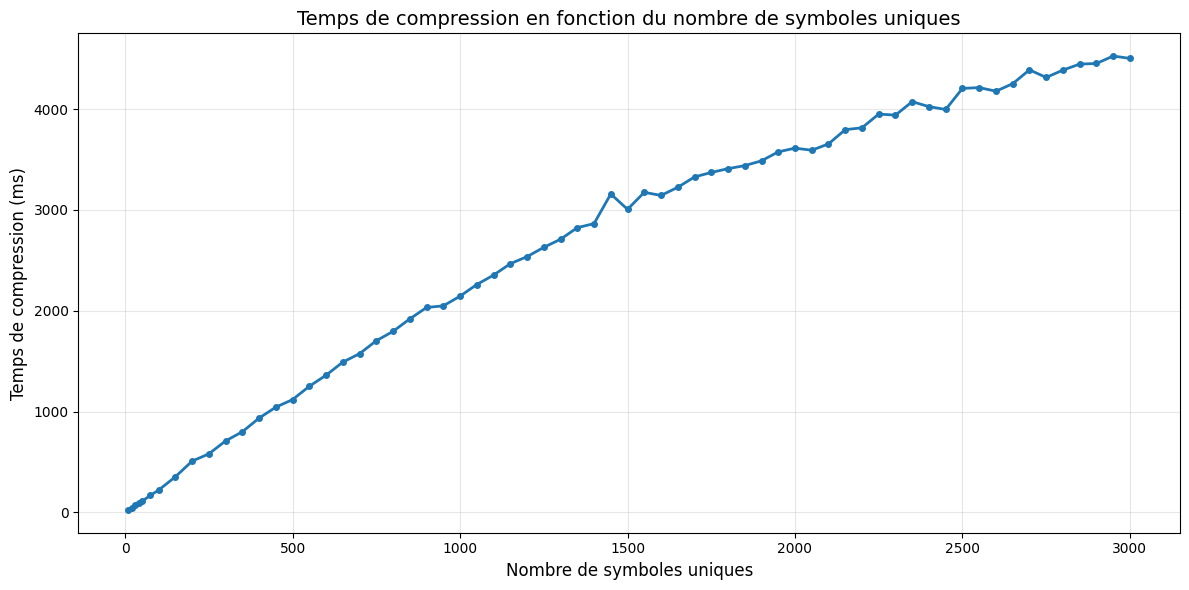

In [35]:
import matplotlib.pyplot as plt
import re

# Lire le fichier de compression
data = []
with open('../compression.txt', 'r') as f:
    for line in f:
        # Chercher les lignes qui correspondent aux fichiers analyse/symboles/sym_*.txt
        if 'analyse/symboles/sym_' in line and '.txt' in line:
            parts = line.strip().split(';')
            filename = parts[0]
            # Extraire la longueur du nom du fichier (avec ou sans -0)
            match = re.search(r'sym_(\d+)(?:-0)?\.txt', filename)
            if match:
                length = int(match.group(1))
                # La dernière valeur est le temps de compression
                compression_time = float(parts[-1])
                data.append((length, compression_time))

# Trier les données par longueur
data.sort(key=lambda x: x[0])

# Séparer les données pour le graphique
lengths = [d[0] for d in data]
times = [d[1] for d in data]

print(f"Nombre de fichiers trouvés: {len(data)}")
if data:
    print(f"Plage de longueurs: {min(lengths)} - {max(lengths)}")
    print(f"Plage de temps: {min(times):.2f} - {max(times):.2f} ms")

# Créer le graphique
plt.figure(figsize=(12, 6))
plt.plot(lengths, times, marker='o', linestyle='-', linewidth=2, markersize=4)
plt.xlabel('Nombre de symboles uniques', fontsize=12)
plt.ylabel('Temps de compression (ms)', fontsize=12)
plt.title('Temps de compression en fonction du nombre de symboles uniques', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Afficher le graphique
plt.show()
